# Text-to-image generation with DiT-S/4

This tutorial walks through the text-conditioned DiT-S/4 built for this project: an adaptation of the
class-conditional DiT (Peebles & Xie, 2023) that generates 256×256 images from text.

We will go through these steps in order:

1. Encode an image into a VAE latent and add noise to it
2. Encode text with CLIP
3. Build DiT-S/4 and look at how text conditions it
4. Run a short training demonstration on a few images
5. Load the trained checkpoint and generate images from text
6. See the effect of the guidance scale and compare samplers
7. Read the published evaluation results

**Requirements.** Run this notebook from a clone of the repository, after `pip install -r requirements.txt jupyter`.
The first run downloads the checkpoint (504 MB) and the CLIP and VAE weights. No GPU or COCO download is needed.
The whole notebook took about 10 minutes on a MacBook Air with MPS. Results may differ slightly between devices.

## Setup

The paper code lives in `dit_base/` and the new code in `src/`, so both go on the Python path.

In [1]:
import csv, json, os, sys, tempfile, textwrap, warnings
from copy import deepcopy
from pathlib import Path

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
warnings.filterwarnings("ignore")

ROOT = Path.cwd() if (Path.cwd() / "dit_base").is_dir() else Path.cwd().parent
sys.path[:0] = [str(ROOT / "dit_base"), str(ROOT / "src")]

import matplotlib.pyplot as plt
import numpy as np
import torch
from diffusers import AutoencoderKL
from diffusers.utils import logging as diffusers_logging
from IPython.display import Markdown, display
from PIL import Image
from transformers import CLIPTextModel, CLIPTokenizer
from transformers.utils import logging as transformers_logging

from dataset_t2i import CocoLatentDataset
from diffusion import create_diffusion
from eval.fetch_checkpoint import download_checkpoint
from models import DiT_models
from sample_t2i import CLIP_NAME, LATENT_SCALE, VAE_NAME, TextToImagePipeline, decode_latents
from train import requires_grad, update_ema

diffusers_logging.set_verbosity_error()
diffusers_logging.disable_progress_bar()
transformers_logging.set_verbosity_error()

device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("Device:", device)


def show(images, titles=None, size=2.4, columns=None):
    # images: tensor (N, 3, H, W) with values in [0, 1]
    images = images.detach().cpu().permute(0, 2, 3, 1).numpy()
    columns = columns or len(images)
    rows = int(np.ceil(len(images) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(size * columns, (size + 0.45) * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for i, (ax, image) in enumerate(zip(axes.flat, images)):
        ax.imshow(image)
        if titles:
            ax.set_title(textwrap.fill(titles[i], int(size * 13)), fontsize=8)
    plt.tight_layout()
    plt.show()

Device: mps


## 1. From an image to a latent

DiT does not work on pixels. A frozen VAE (`stabilityai/sd-vae-ft-ema`) turns a 256×256×3 image into a
4×32×32 latent, multiplied by the scale factor 0.18215. We call this clean latent `z_0`.

We use one of the validation images stored with the evaluation results.

Caption: A man walking into the ocean while holding a surfboard.
Image shape:  (1, 3, 256, 256)
Latent shape: (1, 4, 32, 32)


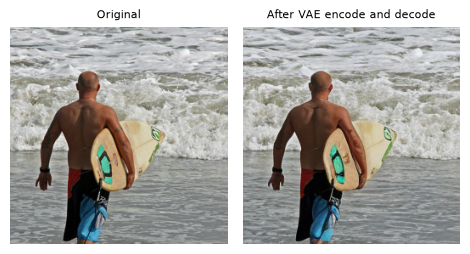

In [2]:
RESULTS = ROOT / "outputs" / "evaluation" / "dit_s4_150k"
examples = json.loads((RESULTS / "muestras" / "indice.json").read_text())


def load_image(relative_path):
    array = np.asarray(Image.open(RESULTS / relative_path).convert("RGB"), dtype=np.float32) / 255
    return torch.from_numpy(array).permute(2, 0, 1)


vae = AutoencoderKL.from_pretrained(VAE_NAME).to(device).eval().requires_grad_(False)

example = examples[1]
x = load_image(example["real"])[None].to(device)
with torch.no_grad():
    z_0 = vae.encode(x * 2 - 1).latent_dist.mode() * LATENT_SCALE

print("Caption:", example["caption"])
print("Image shape: ", tuple(x.shape))
print("Latent shape:", tuple(z_0.shape))
show(torch.cat([x, decode_latents(vae, z_0)]), ["Original", "After VAE encode and decode"])

### Adding noise

Training uses 1000 diffusion steps with a linear schedule (β from 1e-4 to 0.02). `q_sample` produces the noisy
latent `z_t` directly for any step `t`. By the last step, only noise is left: the model has to learn to reverse this.
The patterns below are what the VAE decoder makes of noisy latents.

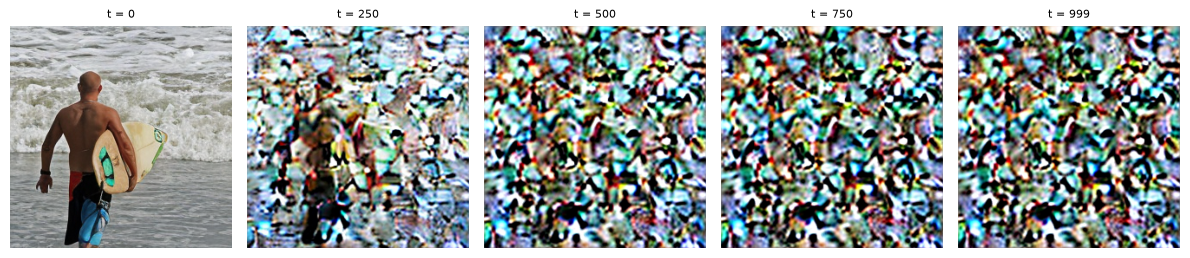

In [3]:
diffusion = create_diffusion(timestep_respacing="")

steps = [0, 250, 500, 750, 999]
torch.manual_seed(0)
noise = torch.randn(z_0.shape)
z_t = torch.cat([diffusion.q_sample(z_0.cpu(), torch.tensor([t]), noise=noise) for t in steps])
show(decode_latents(vae, z_t.to(device)), [f"t = {t}" for t in steps])

## 2. From text to an embedding

A frozen CLIP text encoder (`openai/clip-vit-large-patch14`) turns each caption into a single 768-dimensional
vector, the pooled output `e_pooled`. This one vector is the only information about the text that the model sees.

In [4]:
tokenizer = CLIPTokenizer.from_pretrained(CLIP_NAME)
text_encoder = CLIPTextModel.from_pretrained(CLIP_NAME).to(device).eval().requires_grad_(False)


@torch.no_grad()
def encode_text(texts):
    tokens = tokenizer(texts, padding="max_length", max_length=77, truncation=True, return_tensors="pt").to(device)
    return text_encoder(**tokens).pooler_output.float()


e_pooled = encode_text([example["caption"], "A cat sleeping on a couch", "A cat resting on a sofa"])
similarity = torch.nn.functional.cosine_similarity(e_pooled[1], e_pooled[2], dim=0).item()
different = torch.nn.functional.cosine_similarity(e_pooled[0], e_pooled[1], dim=0).item()
print("e_pooled shape:", tuple(e_pooled.shape))
print(f"Cosine similarity, two similar captions:   {similarity:.3f}")
print(f"Cosine similarity, two different captions: {different:.3f}")

e_pooled shape: (3, 768)
Cosine similarity, two similar captions:   0.908
Cosine similarity, two different captions: 0.167


## 3. The model: DiT-S/4 with adaLN-Zero-Text

The latent is split into 4×4 patches, which gives 64 tokens processed by 12 transformer blocks (hidden size 384,
6 heads). The text enters through adaLN-Zero:

- `TextEmbedder` projects `e_pooled` to 384 dimensions (`y_emb`), replacing DiT's class-label embedding.
- `y_emb` is added to the timestep embedding: `c = t_emb + y_emb`.
- `c` modulates every block.

The output has 8 channels: 4 for the predicted noise `ε_θ` and 4 for the predicted variance `Σ_θ`. Because of
the adaLN-Zero initialization, a new model outputs all zeros.

In [5]:
torch.manual_seed(0)
model = DiT_models["DiT-S/4"](input_size=32, text_dim=768, class_dropout_prob=0.15)

z = torch.randn(2, 4, 32, 32)
t = torch.randint(0, 1000, (2,))
y = torch.randn(2, 768)
with torch.no_grad():
    output = model.eval()(z, t, y)

print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
print("Output shape:", tuple(output.shape))
print("All zeros at initialization:", bool((output == 0).all()))
print(model.y_embedder)

Parameters: 33,003,776
Output shape: (2, 8, 32, 32)
All zeros at initialization: True
TextEmbedder(
  (proj): Sequential(
    (0): Linear(in_features=768, out_features=384, bias=True)
    (1): SiLU()
    (2): Linear(in_features=384, out_features=384, bias=True)
  )
)


### Text dropout and classifier-free guidance

During training, 15% of captions are replaced by a null embedding `∅`, so the model also learns to predict noise
without text. At sampling time, both predictions are combined with a guidance scale `s`:

$$\epsilon = \epsilon_{\text{uncond}} + s \cdot (\epsilon_{\text{cond}} - \epsilon_{\text{uncond}})$$

With `s = 1` only the conditional prediction is used. Larger values push the image further towards the text.

In [6]:
embedder = model.y_embedder
batch = torch.ones(100_000, 768)
dropped = embedder.token_drop(batch)
rate = (dropped == embedder.null_embedding).all(dim=1).float().mean().item()
print(f"Measured dropout rate: {rate:.4f}")

Measured dropout rate: 0.1484


## 4. A short training demonstration

The real run trained on precomputed features of 45,174 images. Here we build the same kind of features for the
8 stored validation images, in the format `extract_features.py` writes, and load them with the project's `CocoLatentDataset`.

For each image, `latents.npy` holds the VAE mean and standard deviation for the original and the flipped view, and
`e_pooled.npy` holds 5 caption embeddings. Each example here has one stored caption, so we repeat it.

In [7]:
images = torch.stack([load_image(e["real"]) for e in examples]).to(device)
captions = [e["caption"] for e in examples]


def latent_stats(batch):
    with torch.no_grad():
        posterior = vae.encode(batch * 2 - 1).latent_dist
    return torch.cat([posterior.mean, posterior.std], dim=1).cpu().numpy().astype(np.float16)


features = Path(tempfile.mkdtemp())
np.save(features / "latents.npy", np.stack([latent_stats(images), latent_stats(images.flip(-1))], axis=1))
np.save(features / "e_pooled.npy", encode_text(captions)[:, None].repeat(1, 5, 1).cpu().numpy().astype(np.float16))
np.save(features / "image_ids.npy", np.array([e["image_id"] for e in examples]))

dataset = CocoLatentDataset(feature_dir=features)
sample_z_0, sample_e = dataset[0]
print("Images in the dataset:", len(dataset))
print("z_0:", tuple(sample_z_0.shape), "| e_pooled:", tuple(sample_e.shape))

Images in the dataset: 8
z_0: (4, 32, 32) | e_pooled: (768,)


The training step matches `src/train.py`: sample a random `t`, call `training_losses`, and optimize with AdamW
(lr 1e-4) while keeping an EMA copy of the weights. The loss combines MSE on `ε_θ` with the variational bound
term `vb` for `Σ_θ`.

This only shows that the pieces work together. It is far too short to produce a useful model, and the falling loss
on 8 images says nothing about the quality of the real run. It runs on the CPU.

step   1 | loss 1.0160 | mse 1.0015 | vb 0.0144


step  25 | loss 0.8625 | mse 0.8521 | vb 0.0104


step  50 | loss 0.4012 | mse 0.3973 | vb 0.0039


step  75 | loss 0.1329 | mse 0.1317 | vb 0.0012


step 100 | loss 0.5206 | mse 0.5039 | vb 0.0167


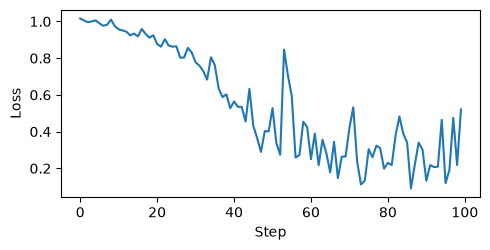

In [8]:
torch.manual_seed(0)
model = DiT_models["DiT-S/4"](input_size=32, text_dim=768, class_dropout_prob=0.15)
ema = deepcopy(model)
requires_grad(ema, False)
update_ema(ema, model, decay=0)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=0)
loader = torch.utils.data.DataLoader(dataset, batch_size=8, shuffle=True, drop_last=True)

history = []
model.train()
for step in range(1, 101):
    z_0_batch, e_batch = next(iter(loader))
    t = torch.randint(0, diffusion.num_timesteps, (len(z_0_batch),))
    losses = diffusion.training_losses(model, z_0_batch, t, dict(y=e_batch))
    loss = losses["loss"].mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    update_ema(ema, model)
    history.append(loss.item())
    if step == 1 or step % 25 == 0:
        print(f"step {step:3d} | loss {loss.item():.4f} | mse {losses['mse'].mean().item():.4f} | vb {losses['vb'].mean().item():.4f}")

plt.figure(figsize=(5, 2.6))
plt.plot(history)
plt.xlabel("Step")
plt.ylabel("Loss")
plt.tight_layout()
plt.show()

## 5. Generating images with the trained model

Now we load the trained checkpoint: EMA weights after 150,000 steps. `download_checkpoint` verifies its SHA-256.

`allow_zero_null=True` is required for this checkpoint. Its `∅` is all zeros, because the training run did not load
the planned CLIP embedding of the empty string. The same `∅` must be used at sampling time, so it is taken from the checkpoint.

In [9]:
checkpoint = download_checkpoint(ROOT / "checkpoints" / "david" / "last.pt")
pipe = TextToImagePipeline.from_checkpoint(checkpoint, device, allow_zero_null=True)

print("Training step:", pipe.training.get("step"))
print("Null condition:", pipe.null_condition)
print("SHA-256:", pipe.checkpoint_sha256)

Training step: 150000
Null condition: zeros_from_training_checkpoint
SHA-256: f693fd7391979856e7059994643e755239276ba5d66a31becf1ebf1e18e93c6b


These are the 8 fixed prompts used to monitor training, with DPM-Solver++ (20 steps), `s = 4` and seed 0.

The model was trained only on images with people, with crops around them, and it is the smallest DiT variant. Results
are limited: expect only a partial match with the text and clear defects in shape and composition.

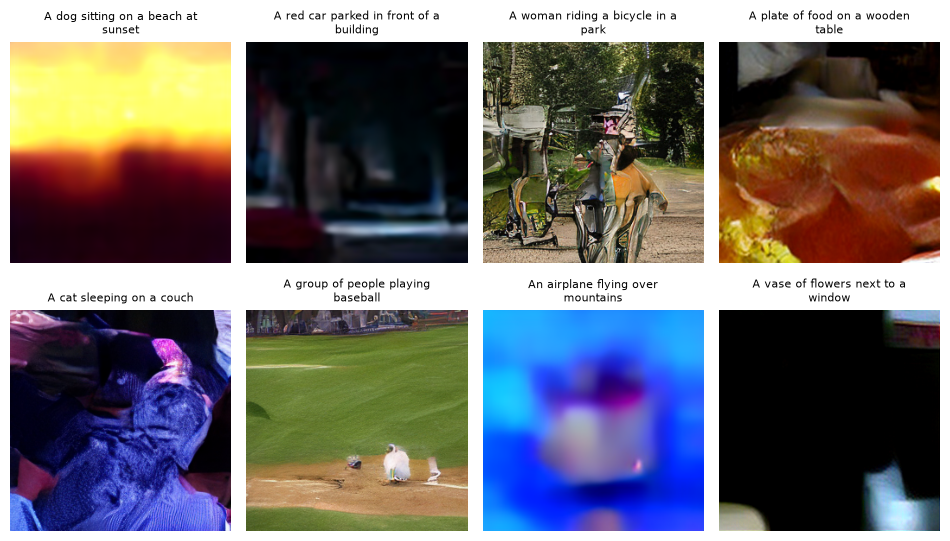

In [10]:
prompts = [
    "A dog sitting on a beach at sunset", "A red car parked in front of a building",
    "A woman riding a bicycle in a park", "A plate of food on a wooden table",
    "A cat sleeping on a couch", "A group of people playing baseball",
    "An airplane flying over mountains", "A vase of flowers next to a window",
]
generated = pipe.generate(prompts, sampler="dpm", steps=20, cfg_scale=4.0, seed=0)
show(generated, prompts, columns=4)

Try your own prompt by changing the text below.

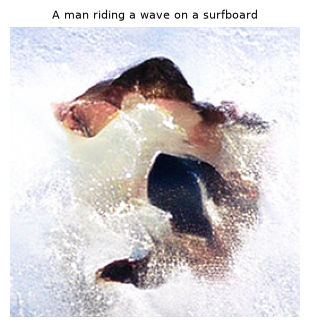

In [11]:
my_prompt = "A man riding a wave on a surfboard"
show(pipe.generate([my_prompt], sampler="dpm", steps=20, cfg_scale=4.0, seed=0), [my_prompt], size=3.2)

## 6. Guidance scale and samplers

### Guidance scale

We keep the prompt and the seed fixed and change only `s`.

A group of people playing baseball


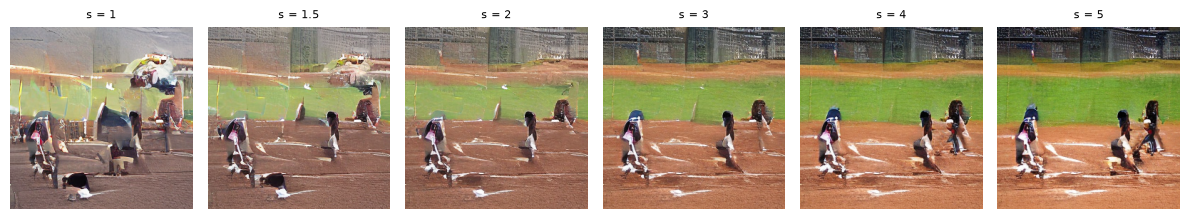

In [12]:
prompt = "A group of people playing baseball"
scales = [1.0, 1.5, 2.0, 3.0, 4.0, 5.0]
images = torch.cat([pipe.generate([prompt], sampler="dpm", steps=20, cfg_scale=s, seed=0) for s in scales])
print(prompt)
show(images, [f"s = {s:g}" for s in scales], size=2.0)

### DPM-Solver++ and DDPM

The project evaluates two samplers: DPM-Solver++ with 20 steps, and DDPM with 250 steps. Both start from the same noise here but follow different paths, so the images differ.

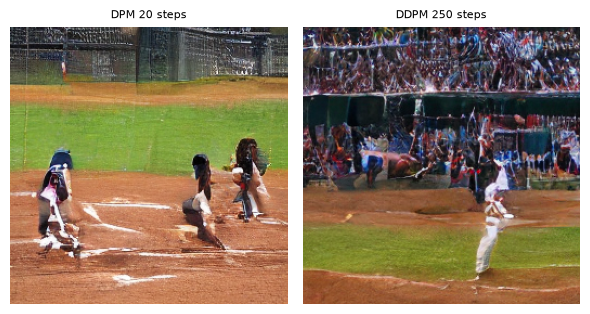

In [13]:
results, titles = [], []
for sampler, steps in [("dpm", 20), ("ddpm", 250)]:
    results.append(pipe.generate([prompt], sampler=sampler, steps=steps, cfg_scale=4.0, seed=0))
    titles.append(f"{sampler.upper()} {steps} steps")
show(torch.cat(results), titles, size=3.0)

## 7. Published evaluation results

The evaluation used the same checkpoint on 10,000 val2014 images, not filtered for people, with a center crop and a
single seed. The training data was different (images with people, cropped around them), which limits how the
absolute values can be read.

These cells only read the stored results, so they do not repeat the evaluation. Generating the 72,000 images takes far
too long for a tutorial; the README lists the commands.

| Sampler | Steps | s | FID-10K | CLIP L/14 | CLIP B/32 |
|---|---:|---:|---:|---:|---:|
| DPM | 20 | 1 | 98.44 | 15.35 | 21.07 |
| DPM | 20 | 1.5 | 87.02 | 16.25 | 22.17 |
| DPM | 20 | 2 | 79.05 | 16.92 | 22.93 |
| DPM | 20 | 3 | 71.98 | 17.81 | 23.78 |
| DPM | 20 | 4 | 71.22 | 18.27 | 24.11 |
| DPM | 20 | 5 | 73.23 | 18.47 | 24.21 |
| DDPM | 250 | 4 | 76.66 | 18.32 | 24.17 |

CLIP Score of the real images: 25.56 (L/14), 30.15 (B/32)


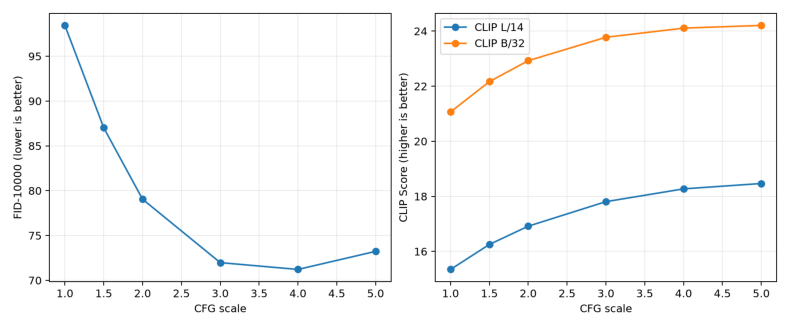

In [14]:
with open(RESULTS / "resultados.csv") as stream:
    rows = [row for row in csv.DictReader(stream) if int(row["count"]) == 10000]

table = ["| Sampler | Steps | s | FID-10K | CLIP L/14 | CLIP B/32 |", "|---|---:|---:|---:|---:|---:|"]
for row in rows:
    table.append(f"| {row['sampler'].upper()} | {row['steps']} | {float(row['cfg_scale']):g} | {float(row['fid']):.2f} "
                 f"| {float(row['clip_l14']):.2f} | {float(row['clip_b32']):.2f} |")
display(Markdown("\n".join(table)))

real = json.loads((RESULTS / "analisis_complementario" / "clip_global.json").read_text())["scores"]["real"]
print(f"CLIP Score of the real images: {real['clip_l14']:.2f} (L/14), {real['clip_b32']:.2f} (B/32)")

figure = plt.imread(RESULTS / "figuras" / "cfg_metrics.png")
plt.figure(figsize=(10, 4))
plt.imshow(figure)
plt.axis("off")
plt.show()

With this checkpoint, set and seed, `s = 4` has the lowest FID-10K in the sweep, and CLIP Score rises with `s` up to 5.
CLIP Score is not a percentage of correct matches.

### Images with and without people

The stored analysis splits the same evaluation (DPM-Solver++ 20, `s = 4`) into two balanced groups, using COCO's person
annotations. These FID values use 4,750 images per group, so they must not be compared with FID-10K. The difference
is descriptive: it does not prove the training filter is the cause.

In [15]:
with open(RESULTS / "analisis_complementario" / "metricas_grupos.csv") as stream:
    groups = list(csv.DictReader(stream))

table = ["| Group | N | FID-N | CLIP L/14 generated | CLIP L/14 real |", "|---|---:|---:|---:|---:|"]
for row in groups:
    name = row["group"].replace("_", " ").capitalize()
    table.append(f"| {name} | {row['count']} | {float(row['fid']):.2f} "
                 f"| {float(row['generated_clip_l14']):.2f} | {float(row['real_clip_l14']):.2f} |")
display(Markdown("\n".join(table)))

| Group | N | FID-N | CLIP L/14 generated | CLIP L/14 real |
|---|---:|---:|---:|---:|
| With person annotations | 4750 | 56.31 | 19.76 | 25.58 |
| Without person annotations | 4750 | 116.30 | 16.61 | 25.52 |

### Real and generated examples

These stored examples come from the evaluation run (DPM-Solver++ 20, `s = 4`) and were not selected for quality.

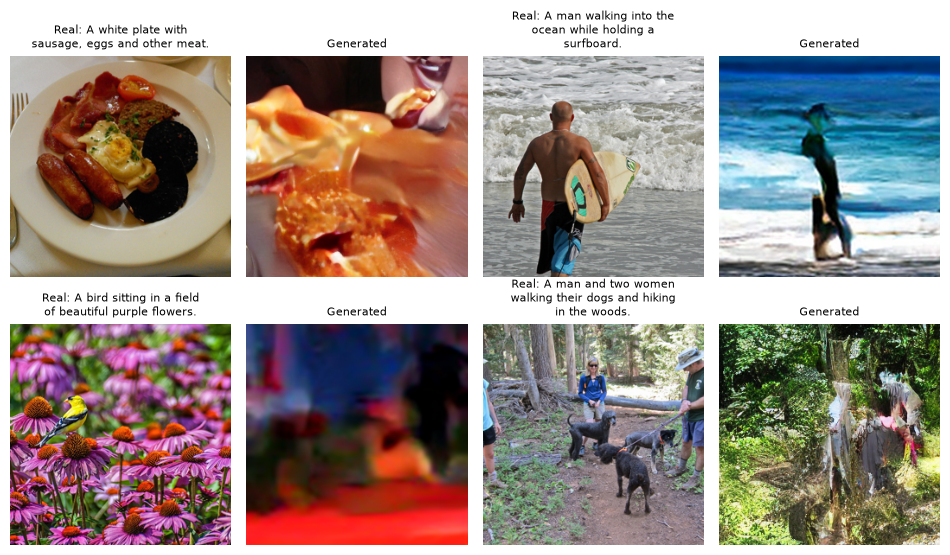

In [16]:
pairs = []
titles = []
for e in examples[:4]:
    pairs += [load_image(e["real"]), load_image(e["generated"]["final_dpm_cfg_4"])]
    titles += [f"Real: {e['caption']}", "Generated"]
show(torch.stack(pairs), titles, columns=4, size=2.4)

## Summary

We followed the full path of the model: image to latent, text to `e_pooled`, conditioning through `c = t_emb + y_emb`,
training steps with the hybrid loss, and generation with classifier-free guidance.

To reproduce the whole project at full scale, follow the steps in the repository's `README.md`.